In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
import numpy as np
import random
import re
import unicodedata
from torch.utils.data import Dataset, DataLoader
import csv
from collections import Counter
import ast
import matplotlib.ticker as ticker
import time
import math
import matplotlib.pyplot as plt
import pandas as pd, ast, re
import nltk
from torch.nn.utils.rnn import pad_sequence


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
def parse_list_column(col):
    try:
        return ast.literal_eval(col) if isinstance(col, str) and col.startswith('[') else []
    except Exception:
        return []

def preprocess_ingredients(ings):
    tokens = []
    for ing in ings:
        tokens.extend(re.findall(r"\b\w+\b", ing.lower()))
    return tokens


def preprocess_recipe(recipe):
    sentences = []
    for step in recipe:
        sentences.extend([sent.strip().lower() for sent in re.split(r'[.!?]', step) if sent.strip()])
    return sentences

def build_vocab(sequences):
    counter = Counter(w for seq in sequences for w in seq)
    vocab = {'PAD': 0, 'SOS': 1, 'EOS': 2, 'UNK': 3}
    idx = 4
    for word, _ in counter.most_common():
        vocab[word] = idx
        idx += 1
    return vocab


def indexes_from_sentence(vocab, sentence):
    return [vocab['SOS']] + [vocab.get(word, vocab['UNK']) for word in sentence] + [vocab['EOS']]

def tensor_from_sentence(vocab, sentence, max_len=None):
    indexes = indexes_from_sentence(vocab, sentence)
    return torch.tensor(indexes, dtype=torch.long)

def tensors_from_pair(pair, ingredient_vocab, recipe_vocab):
    input_tensor = tensor_from_sentence(ingredient_vocab, pair[0])
    target_tensor = tensor_from_sentence(recipe_vocab, pair[1])
    return (input_tensor, target_tensor)

In [4]:
class RecipeDataset(Dataset):
    def __init__(self, pairs, ingredient_vocab, recipe_vocab, max_len):
        self.pairs = pairs
        self.ingredient_vocab = ingredient_vocab
        self.recipe_vocab = recipe_vocab
        self.max_len = max_len
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        ing_tokens = self.pairs[idx][0]
        rec_tokens = self.pairs[idx][1]
        inp = tensor_from_sentence(self.ingredient_vocab, ing_tokens, self.max_len)
        out = tensor_from_sentence(self.recipe_vocab, rec_tokens, self.max_len)
        return inp, out

In [5]:

class baseline_Encoder_RNN1(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(baseline_Encoder_RNN1, self).__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(input_size, hidden_size, padding_idx=0)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)

    def forward(self, input_seq):

        embedded = self.embedding(input_seq)
        _, hidden = self.gru(embedded)
        return hidden

class baseline_Decoder_RNN1(nn.Module):
    def __init__(self, hidden_size, output_size):
        super(baseline_Decoder_RNN1, self).__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(output_size, hidden_size, padding_idx=0)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim=-1)

    def forward(self, input_step, hidden):

        embedded = self.embedding(input_step)
        output, hidden = self.gru(embedded, hidden)  # output: (batch_size, 1, hidden_size)
        output = self.out(output)
        output = self.softmax(output)  # (batch_size, 1, output_size)
        return output, hidden


In [6]:
train_df = pd.read_csv("train.csv", nrows=90000)
train_df["Ingredients"] = train_df["Ingredients"].apply(ast.literal_eval)
train_df["Recipe"] = train_df["Recipe"].apply(ast.literal_eval)
# Apply preprocessing
train_df["ingredient_tokens"] = train_df["Ingredients"].apply(preprocess_ingredients)
train_df["recipe_tokens"] = train_df["Recipe"].apply(preprocess_recipe)

# Combine into (input, target) pairs
train_pairs = list(zip(train_df["ingredient_tokens"], train_df["recipe_tokens"]))
ingredient_vocab = build_vocab(train_df["ingredient_tokens"].tolist())
recipe_vocab = build_vocab(train_df["recipe_tokens"].tolist())


# Load and preprocess test.csv
test_df = pd.read_csv("test.csv")
test_df["Ingredients"] = test_df["Ingredients"].apply(ast.literal_eval)
test_df["Recipe"] = test_df["Recipe"].apply(ast.literal_eval)
test_df["ingredient_tokens"] = test_df["Ingredients"].apply(preprocess_ingredients)
test_df["recipe_tokens"] = test_df["Recipe"].apply(preprocess_recipe)

# Create test pairs
test_pairs = list(zip(test_df["ingredient_tokens"], test_df["recipe_tokens"]))

# Convert to tensor pairs
test_tensor_pairs = [tensors_from_pair(pair, ingredient_vocab, recipe_vocab) for pair in test_pairs]


In [7]:
print("Ingredient vocab size:", len(ingredient_vocab))
print("Recipe vocab size:", len(recipe_vocab))



Ingredient vocab size: 7252
Recipe vocab size: 346283


In [8]:
def collate_fn(batch):
    inputs, targets = zip(*batch)
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=0)
    return inputs_padded, targets_padded

max_len = 100
train_dataset = RecipeDataset(train_pairs, ingredient_vocab, recipe_vocab, max_len=max_len)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, collate_fn=collate_fn)


In [9]:
def train_batch(inputs, targets, encoder, decoder, enc_opt, dec_opt, criterion, teacher_forcing_ratio=None):
    inputs, targets = inputs.to(device), targets.to(device)
    batch_size, seq_len = targets.size()
    enc_opt.zero_grad()
    dec_opt.zero_grad()

    encoder_hidden = encoder(inputs)  # shape: (1, batch, hidden)

    decoder_input = torch.full((batch_size, 1), recipe_vocab['SOS'], dtype=torch.long, device=device)
    decoder_hidden = encoder_hidden

    loss = 0

    for t in range(seq_len):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
        if torch.any(targets[:, t] >= decoder_output.size(-1)):
            print("Target index out of bounds at timestep", t)
            print("Max target:", targets[:, t].max().item())
            print("Decoder output size:", decoder_output.size())
            raise ValueError("Target token exceeds decoder vocabulary size.")

        loss += criterion(decoder_output.squeeze(1), targets[:, t])
        use_teacher_forcing = random.random() < teacher_forcing_ratio
        top1 = decoder_output.argmax(-1)
        decoder_input = targets[:, t].unsqueeze(1) if use_teacher_forcing else top1

    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), max_norm=5)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), max_norm=5)
    enc_opt.step()
    dec_opt.step()

    return loss.item() / seq_len


In [10]:
def get_teacher_forcing_ratio(step):
    return 0.1

In [11]:
def showPlot(points):
    plt.figure(figsize=(8, 5))
    plt.plot(points)
    plt.title("Training Loss")
    plt.xlabel("Iterations (per plot_every)")
    plt.ylabel("Loss")
    plt.grid(True)
    ax = plt.gca()
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.show()


In [12]:
def train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=10):
    encoder.train()
    decoder.train()
    all_losses = []
    enc_opt = torch.optim.Adam(encoder.parameters(), lr=0.001)
    dec_opt = torch.optim.Adam(decoder.parameters(), lr=0.001)
    criterion = nn.NLLLoss(ignore_index=0)

    step = 0
    for epoch in range(1, n_epochs + 1):
        epoch_loss = 0
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            step += 1
            tf_ratio = get_teacher_forcing_ratio(step)
            loss = train_batch(inputs, targets, encoder, decoder, enc_opt, dec_opt, criterion, tf_ratio)
            epoch_loss += loss

        avg_epoch_loss = epoch_loss / len(train_loader)
        all_losses.append(avg_epoch_loss)
        print(f"Epoch {epoch} | TF ratio: {tf_ratio:.2f} | Loss: {avg_epoch_loss:.4f}")
    showPlot(all_losses)
    return all_losses


Epoch 1 | TF ratio: 0.10 | Loss: 9.7516
Epoch 2 | TF ratio: 0.10 | Loss: 8.6946
Epoch 3 | TF ratio: 0.10 | Loss: 8.3454
Epoch 4 | TF ratio: 0.10 | Loss: 8.1197
Epoch 5 | TF ratio: 0.10 | Loss: 7.8500
Epoch 6 | TF ratio: 0.10 | Loss: 7.4726
Epoch 7 | TF ratio: 0.10 | Loss: 6.9678
Epoch 8 | TF ratio: 0.10 | Loss: 6.3850
Epoch 9 | TF ratio: 0.10 | Loss: 5.7249
Epoch 10 | TF ratio: 0.10 | Loss: 5.0545


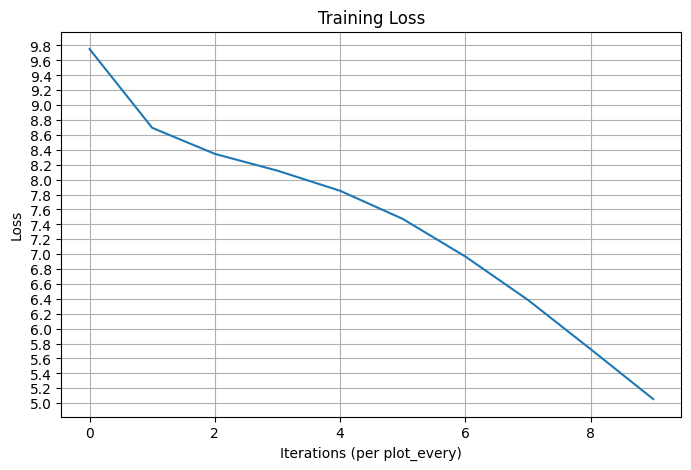

[9.751648096547036,
 8.694590592154487,
 8.345377602249819,
 8.1196571148904,
 7.85000445367615,
 7.4726186598009186,
 6.96775359624406,
 6.385046252413023,
 5.724882759912846,
 5.054482435625434]

In [13]:
encoder = baseline_Encoder_RNN1(len(ingredient_vocab), hidden_size=256).to(device)
decoder = baseline_Decoder_RNN1(hidden_size=256, output_size=len(recipe_vocab)).to(device)

train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=10)


In [14]:
def evaluate_model_loss(encoder, decoder, tensor_pairs, criterion, max_length=100):
    total_loss = 0
    with torch.no_grad():
        for input_tensor, target_tensor in tensor_pairs:
            input_tensor = input_tensor.unsqueeze(0).to(device)
            target_tensor = target_tensor.to(device)

            encoder_hidden = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden

            loss = 0
            for di in range(target_tensor.size(0)):
                decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
                loss += criterion(decoder_output.squeeze(1), target_tensor[di].unsqueeze(0))
                topv, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()

                if topi.item() == recipe_vocab['EOS']:
                    break

            total_loss += loss.item() / target_tensor.size(0)

    return total_loss / len(tensor_pairs)
criterion = nn.NLLLoss(ignore_index=0)
test_loss_baseline1 = evaluate_model_loss(encoder, decoder, test_tensor_pairs, criterion)
print("Baseline 1 Test Loss:", test_loss_baseline1)


Baseline 1 Test Loss: 6.332774355201503


In [15]:
def generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=100):
    input_tensor = input_tensor.unsqueeze(0).to(device)
    encoder_hidden = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
    decoder_hidden = encoder_hidden
    output_tokens = []

    for _ in range(max_length):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
        topv, topi = decoder_output.topk(1, dim=-1)
        token_id = topi.squeeze().item()
        if token_id == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
        output_tokens.append(word)
        decoder_input = torch.tensor([[token_id]], device=device)

    return output_tokens




In [16]:
# Make sure you have an inverse vocab for recipe_vocab
recipe_vocab_inv = {v: k for k, v in recipe_vocab.items()}

# Pick 5 random indices from your test set
random_indices = random.sample(range(len(test_pairs)), 5)

for i, idx in enumerate(random_indices):
    ingredients_tokens, ground_truth_tokens = test_pairs[idx]
    # Prepare input tensor for the model
    input_tensor = tensor_from_sentence(ingredient_vocab, ingredients_tokens, max_len)
    # Generate recipe
    generated_tokens = generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=max_len)
    # Print results
    print(f"--- Example {i+1} (Test Index: {idx}) ---")
    print("Ingredients:", " ".join(ingredients_tokens))
    print("Ground Truth Recipe:", " ".join(ground_truth_tokens))
    print("Generated Recipe:", " ".join(generated_tokens))
    print()

--- Example 1 (Test Index: 611) ---
Ingredients: 3 c water 1 2 tsp salt 1 c macaroni 2 tbsp margarine 1 4 c milk 1 c cube cheese
Ground Truth Recipe: bring water to boil add salt and macaroni; cook until tender drain add margarine or butter, milk and cheese stir until all is melted together
Generated Recipe: SOS combine vegetables in a large bowl

--- Example 2 (Test Index: 208) ---
Ingredients: 1 2 c sugar 1 tsp dry mustard 1 tsp salt 1 4 onion grated 1 3 c vinegar 1 c salad oil 1 tbsp celery seed
Ground Truth Recipe: measure dry ingredients into a small mixing bowl mix sugar, salt and mustard and add onion juice and a small amount of vinegar add oil gradually, then remaining vinegar and celery seed
Generated Recipe: SOS combine

--- Example 3 (Test Index: 380) ---
Ingredients: 1 16 oz can wax beans drained 1 16 oz can green beans drained 1 16 oz can pinto beans drained 1 4 c chopped onion 1 4 c chopped green bell pepper dressing
Ground Truth Recipe: combine wax beans, green beans, pi

In [17]:
#  STEP 1: Install dependencies
!pip install nltk bert-score --quiet
!pip install bert-score

# STEP 2: Import libraries
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from bert_score import score

#  STEP 3: Download NLTK resources
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 125.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 107.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 112.5 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


ValueError: GRU: Expected input to be 2D or 3D, got 4D instead

In [20]:
#  STEP 4: Define your evaluation function
def evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100):
    bleu_scores = []
    meteor_scores = []
    references = []
    candidates = []

    for input_tensor, target_tensor in test_tensor_pairs[:200]:
        input_tensor = input_tensor.unsqueeze(0).to(device)
        target_tensor = target_tensor.to(device)

        # Generate prediction
        encoder_hidden = encoder(input_tensor)
        decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
        decoder_hidden = encoder_hidden
        generated_tokens = []

        for _ in range(max_len):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
            topi = decoder_output.argmax(-1)
            token_id = topi.squeeze().item()
            if token_id == recipe_vocab['EOS']:
                break
            word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
            generated_tokens.append(word)
            decoder_input = topi

        # Convert tensors to tokens
        reference = [next((k for k, v in recipe_vocab.items() if v == idx.item()), "<UNK>")
                     for idx in target_tensor[1:-1]]  # Skip SOS/EOS
        candidate = generated_tokens

        # Evaluate
        if reference and candidate:
            smoothie = SmoothingFunction().method4
            bleu = sentence_bleu([reference], candidate, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)
            meteor = meteor_score([reference], candidate)
            bleu_scores.append(bleu)
            meteor_scores.append(meteor)
            references.append(' '.join(reference))
            candidates.append(' '.join(candidate))

    # BERTScore
    P, R, F1 = score(candidates, references, lang='en', verbose=False)
    bertscore_f1 = F1.mean().item()

    # Final print
    print("\n=== Average Scores on Test Set ===")
    print(f"BLEU-4: {sum(bleu_scores)/len(bleu_scores):.4f}" if bleu_scores else "BLEU-4: No valid scores")
    print(f"METEOR: {sum(meteor_scores)/len(meteor_scores):.4f}" if meteor_scores else "METEOR: No valid scores")
    print(f"BERTScore (F1): {bertscore_f1:.4f}")


# STEP 5: Call the function with your model and test pairs
evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Average Scores on Test Set ===
BLEU-4: 0.0002
METEOR: 0.0009
BERTScore (F1): 0.7960


In [31]:
df = pd.read_csv("generated_34557326.csv")
print(df.head())
print(df.columns)


                                         Ingredients   Recipe - Baseline 1  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...                   NaN   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...                   NaN   
2  ["1 large box lemon jello", "1 large can crush...                   NaN   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...                   NaN   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...                   NaN   

    Recipe - Baseline 2   Recipe - Mild Ext 1   Recipe - Mild Ext 2  \
0                   NaN                   NaN                   NaN   
1                   NaN                   NaN                   NaN   
2                   NaN                   NaN                   NaN   
3                   NaN                   NaN                   NaN   
4                   NaN                   NaN                   NaN   

    Recipe - Spicy Ext 1   Recipe - Spicy Ext 2  
0                    NaN                    NaN  
1   

In [35]:
import pandas as pd
import ast, re, torch
from tqdm import tqdm



def clean_and_tokenize_ingredients(ingredient_text):
    try:
        ingredients = ast.literal_eval(ingredient_text) if isinstance(ingredient_text, str) else []
    except:
        ingredients = []
    tokens = []
    for ing in ingredients:
        tokens.extend(re.findall(r'\b\w+\b', ing.lower()))
    return tokens

def generate_recipe(ingredient_tokens, encoder, decoder, ingredient_vocab, recipe_vocab, max_len=100):
    input_indexes = [ingredient_vocab.get(w, ingredient_vocab['UNK']) for w in ingredient_tokens]
    input_tensor = torch.tensor([ingredient_vocab['SOS']] + input_indexes + [ingredient_vocab['EOS']],
                                dtype=torch.long).unsqueeze(0).to(device)

    encoder_hidden = encoder(input_tensor)
    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
    decoder_hidden = encoder_hidden
    output_words = []

    for _ in range(max_len):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == next_token), "<UNK>")
        output_words.append(word)
        decoder_input = topi.detach()
    return ' '.join(output_words)

# Load CSV
df = pd.read_csv("generated_34557326.csv")

# Example: fill "Recipe - Baseline 1" column
baseline1_outputs = []
for ing_text in tqdm(df["Ingredients"], desc="Generating Baseline 1"):
    tokens = clean_and_tokenize_ingredients(ing_text)
    gen1 = generate_recipe(tokens, encoder, decoder, ingredient_vocab, recipe_vocab)
    baseline1_outputs.append(gen1)

df["Recipe - Baseline 1"] = baseline1_outputs

# Save updated file as CSV
df.to_csv("generated_filled.csv", index=False, encoding='utf-8-sig')
print("Updated predictions written to: generated_filled.csv")


Generating Baseline 1: 100%|██████████| 1081/1081 [00:08<00:00, 120.40it/s]

Updated predictions written to: generated_filled.csv


In [36]:
df = pd.read_csv("generated_filled.csv")
print(df[["Ingredients", "Recipe - Baseline 1"]].head(10))


                                         Ingredients  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...   
2  ["1 large box lemon jello", "1 large can crush...   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...   
5  ["1 c. white sugar", "1 pkg. chopped sugared d...   
6  ["1 (10 oz.) bag chopped broccoli", "4 chicken...   
7  ["1 bunch broccoli, chopped", "1 medium purple...   
8  ["1/2 c. each dried pinto beans, pink beans an...   
9  ["2 c. sugar", "1/2 tsp. salt", "1 c. hot wate...   

                                 Recipe - Baseline 1  
0                            SOS soften cream cheese  
1                       SOS brown ground beef; drain  
2  SOS alternate adding mixtures from bowls #2 an...  
3  SOS combine both mixtures together add chicken...  
4                    SOS preheat oven to 350 degrees  
5                 SOS slice almonds, citron and figs 

In [33]:
print(df.head())
print(df.columns[1])

                                         Ingredients   Recipe - Baseline 1  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...                   NaN   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...                   NaN   
2  ["1 large box lemon jello", "1 large can crush...                   NaN   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...                   NaN   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...                   NaN   

    Recipe - Baseline 2   Recipe - Mild Ext 1   Recipe - Mild Ext 2  \
0                   NaN                   NaN                   NaN   
1                   NaN                   NaN                   NaN   
2                   NaN                   NaN                   NaN   
3                   NaN                   NaN                   NaN   
4                   NaN                   NaN                   NaN   

    Recipe - Spicy Ext 1   Recipe - Spicy Ext 2  \
0                    NaN                    NaN   
1 